In [ ]:
# Force reimport all custom modules (run this after editing .py files)
import sys
import os
import importlib

DRIVE_PATH = "/content/drive/MyDrive/Flux_Autosteering"
TOOLKIT_PATH = os.path.join(DRIVE_PATH, "experiments", "flux_concept_sweep")
for path in (DRIVE_PATH, TOOLKIT_PATH):
    if path not in sys.path:
        sys.path.append(path)

# Remove cached modules
modules_to_reload = [
    "flux_steering.model_utils", "flux_steering.vector_utils", "flux_steering.hook_utils",
    "flux_steering.config", "flux_steering.cache_utils", "flux_steering.file_utils",
    "flux_steering.image_utils", "flux_steering.visualization_utils",
]

for module_name in modules_to_reload:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Now reimport with fresh versions
from flux_steering.model_utils import load_flux_model, setup_device
from flux_steering.vector_utils import contrastive_steering_vector, generate_steered_image
from flux_steering.hook_utils import get_layer, make_steering_hook, register_steering_range

print("Modules reloaded successfully!")

✅ Modules reloaded successfully!


In [ ]:
del sys.modules['flux_steering.vector_utils']
from flux_steering.vector_utils import contrastive_steering_vector, generate_steered_image

In [ ]:
!pip install transformers==4.45.0

import torch
from PIL import Image
import matplotlib.pyplot as plt
import sys
import os

DRIVE_PATH = "/content/drive/MyDrive/Flux_Autosteering"
sys.path.append(DRIVE_PATH)

os.chdir(DRIVE_PATH)
from flux_steering.model_utils import load_flux_model, setup_device
from flux_steering.vector_utils import contrastive_steering_vector, generate_steered_image

DEVICE = setup_device()
pipe = load_flux_model(device=DEVICE)

print("\n✅ Model loaded and ready!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 108.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 115.8 MB/s eta 0:00:00
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.1
    Uninstalling tokenizers-0.22.1:
      Successfully uninstalled tokenizers-0.22.1
  Attempting uninstall: transformers
    Found existing installation: transformers 4.57.1
    Uninstalling transformers-4.57.1:
      Successfully uninstalled transformers-4.57.1
Using device: cuda


model_index.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/782 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/19.9k [00:00<?, ?B/s]

... (20 outputs left out)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

You set `add_prefix_space`. The tokenizer needs to be converted from the slow tokenizers


✅ Model and scheduler loaded successfully.

✅ Model loaded and ready!


In [ ]:
# ============================================================================
# UnlearnCanvas Prompt Configuration
# ============================================================================

# Choose your style and object
style = "Watercolor"  # Can be: Van_Gogh, Monet, Impressionism, Watercolor, etc.
object_class = "Landscape"  # Can be: Flowers, Human, Dogs, Cats, Waterfalls, etc.

# Create UnlearnCanvas format prompt
prompt = f"An {object_class} image in {style} style."
# Settings
HEIGHT = 512
WIDTH = 768
NUM_INFERENCE_STEPS = 4  # Flux Schnell uses 4 steps
SEED = 42

print(f"Style: {style}")
print(f"Object: {object_class}")
print(f"Prompt: {prompt}")
print(f"\nImage size: {HEIGHT}x{WIDTH}")
print(f"Inference steps: {NUM_INFERENCE_STEPS}")
print(f"Seed: {SEED}")


Style: Watercolor
Object: Landscape
Prompt: An Landscape image in Watercolor style.

Image size: 512x768
Inference steps: 4
Seed: 42


In [ ]:
# Imports
from flux_steering.cache_utils import VectorCache
from flux_steering.config import Config, default_config
from pathlib import Path

# Setup config and cache
config = default_config
config.setup_paths()
new_cache_dir = Path('/content/drive/MyDrive/Flux_Autosteering/new_cache')
new_manifest = Path('/content/drive/MyDrive/Flux_Autosteering/new_cache/manifest.jsonl')
vector_cache = VectorCache(new_cache_dir, new_manifest)

print(f"✅ Vector cache initialized")
print(f"   Cache directory: {config.cache_dir}")
print(f"   Manifest: {config.manifest_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Vector cache initialized
   Cache directory: /content/drive/MyDrive/Flux_Autosteering/results/concept_vectors
   Manifest: /content/drive/MyDrive/Flux_Autosteering/results/concept_vectors/manifest.jsonl


In [ ]:
# Clear Vector Cache
import shutil

# Delete all cached vectors
cache_dir = vector_cache.cache_dir
manifest_path = vector_cache.manifest_path

# Clear cache directory
if cache_dir.exists():
    shutil.rmtree(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    print(f"✅ Cleared cache directory: {cache_dir}")

# Clear manifest
if manifest_path.exists():
    manifest_path.unlink()
manifest_path.touch()
print(f"✅ Cleared manifest: {manifest_path}")

# Reset internal cache
vector_cache._manifest_keys = set()

print("🎉 Cache completely cleared!")


✅ Cleared cache directory: /content/drive/MyDrive/Flux_Autosteering/new_cache
✅ Cleared manifest: /content/drive/MyDrive/Flux_Autosteering/new_cache/manifest.jsonl
🎉 Cache completely cleared!


In [ ]:
# ============================================================================
# OBJECT REMOVAL TEST - UnlearnCanvas Benchmark
# ============================================================================
"""
This cell demonstrates object removal (not style removal).
For UnlearnCanvas, this tests the model's ability to suppress specific objects.

Example use cases:
- Remove "dogs" from generated images
- Remove "cars" from landscape scenes
- Remove "people" from architectural images
- Remove specific objects like "glasses", "hats", etc.
"""

# Configuration
object_to_remove = "dogs"  # Object to suppress/remove
scene_context = "in a park"  # Context for the scene
HEIGHT = 512
WIDTH = 768
NUM_INFERENCE_STEPS = 4
SEED = 42

# Layer configuration for object removal
LAYER_INDICES = list(range(0, 57))  # All layers (you can narrow this down)
STREAM = "both"
NUM_SEEDS = 100  # More seeds for better stability

print("="*70)
print("🎯 OBJECT REMOVAL TEST")
print("="*70)
print(f"Object to remove: {object_to_remove}")
print(f"Scene context: {scene_context}")
print(f"Target layers: {LAYER_INDICES[0]} to {LAYER_INDICES[-1]}")
print(f"Averaging over {NUM_SEEDS} seeds")
print("="*70)

# ============================================================================
# Step 1: Create Steering Vector for Object Suppression
# ============================================================================

# For object removal, we want to steer AWAY from the object
pos_prompt = f"A photo of {object_to_remove} {scene_context}"  # Object to suppress
neg_prompt = f"A photo {scene_context}"  # Scene WITHOUT the object

print(f"\n📋 Prompts:")
print(f"  Positive (suppress): '{pos_prompt}'")
print(f"  Negative (keep):     '{neg_prompt}'")

# ============================================================================
# Try to Load from Cache First
# ============================================================================

concept_name = f"remove_{object_to_remove}_{scene_context.replace(' ', '_')}"
print(f"\n📦 Checking cache for concept: '{concept_name}'...")

steering_vector = vector_cache.load_layer_range(
    concept=concept_name,
    start_layer=LAYER_INDICES[0],
    end_layer=LAYER_INDICES[-1],
    stream="both"
)

# Check which layers we still need to extract
missing_layers = [i for i in LAYER_INDICES if i not in steering_vector]

if not missing_layers:
    print(f"✅ Loaded all {len(steering_vector)} vectors from cache!")
    print(f"   Skipping vector generation (already cached)")
else:
    if steering_vector:
        print(f"📦 Found {len(steering_vector)} cached vectors")
    print(f"🧭 Need to generate {len(missing_layers)} missing layers: {missing_layers[:10]}{'...' if len(missing_layers) > 10 else ''}")

    # Generate missing vectors using improved API (single function call!)
    import time

    print(f"\n🧭 Generating {len(missing_layers)} vectors averaged over {NUM_SEEDS} seeds...")
    start_time = time.time()

    # NEW: Function handles averaging internally - much cleaner!
    new_vectors = contrastive_steering_vector(
        transformer=pipe.transformer,
        layer_indices=missing_layers,
        pos_prompt=pos_prompt,
        neg_prompt=neg_prompt,
        pipe=pipe,
        stream=STREAM,
        steps=NUM_INFERENCE_STEPS,
        H=HEIGHT,
        W=WIDTH,
        seed=SEED,
        num_seeds=NUM_SEEDS      # Automatically averages over multiple seeds
    )

    # Merge new vectors with existing cached vectors
    for layer_idx in missing_layers:
        steering_vector[layer_idx] = new_vectors[layer_idx]

    elapsed = time.time() - start_time
    print(f"✅ New vectors created in {elapsed:.1f}s")

    # Save newly generated vectors to cache
    print(f"\n💾 Saving {len(missing_layers)} new vectors to cache...")
    saved_count = 0

    for layer_idx in missing_layers:
        # Save image stream
        if steering_vector[layer_idx]['image'] is not None:
            key_hash, meta = vector_cache.vector_key(
                concept=concept_name,
                layer_idx=layer_idx,
                stream='image',
                pos_prompt=pos_prompt,
                neg_prompt=neg_prompt,
                steps=NUM_INFERENCE_STEPS,
                H=HEIGHT,
                W=WIDTH,
                seed_avg={'base': SEED, 'n': NUM_SEEDS}
            )
            vector_cache.save_vector(steering_vector[layer_idx]['image'], key_hash, meta)
            saved_count += 1

        # Save text stream
        if steering_vector[layer_idx]['text'] is not None:
            key_hash, meta = vector_cache.vector_key(
                concept=concept_name,
                layer_idx=layer_idx,
                stream='text',
                pos_prompt=pos_prompt,
                neg_prompt=neg_prompt,
                steps=NUM_INFERENCE_STEPS,
                H=HEIGHT,
                W=WIDTH,
                seed_avg={'base': SEED, 'n': NUM_SEEDS}
            )
            vector_cache.save_vector(steering_vector[layer_idx]['text'], key_hash, meta)
            saved_count += 1

    print(f"✅ Saved {saved_count} vector components to cache")

print(f"\n🎉 Ready with {len(steering_vector)} steering vectors!")

# ============================================================================
# Step 2: Generate Baseline (WITH object)
# ============================================================================

print(f"\n🎨 Generating BASELINE image (with {object_to_remove})...")
test_prompt = f"A photo of {object_to_remove} {scene_context}"

generator = torch.Generator(device='cuda').manual_seed(SEED)
baseline_image = pipe(
    prompt=test_prompt,
    height=HEIGHT,
    width=WIDTH,
    num_inference_steps=NUM_INFERENCE_STEPS,
    guidance_scale=0.0,
    generator=generator,
).images[0]

baseline_image.save(f"baseline_{object_to_remove}.png")
print(f"✅ Baseline saved: baseline_{object_to_remove}.png")

# ============================================================================
# Step 3: Test Object Removal at Different Weights
# ============================================================================

print(f"\n🎯 Testing object removal with different steering weights...")
print(f"   Negative weights = suppress object (removal)")
print(f"   Positive weights = enhance object (opposite of what we want)")

# Weight sweep - focus on negative weights for suppression
# WEIGHTS = [-1024, -512, -256, -128,-64,-32,  0]
WEIGHTS = [-28, -26, -24, -18, -16, -12, -10, -8, -6, -4, 0]

# Apply steering
START_LAYER = 11
END_LAYER = 32

steered_images = {}

for weight in tqdm(WEIGHTS, desc="Generating steered images"):
    # Register hooks
    hooks = []
    for layer_idx in range(START_LAYER, END_LAYER + 1):
        if layer_idx in steering_vector:
            hook_fn = make_steering_hook(
                steering_vector=steering_vector[layer_idx],
                w=weight,
                steer_target="both"
            )
            _, mod, _ = get_layer(pipe.transformer, layer_idx)
            hooks.append(mod.register_forward_hook(hook_fn))

    try:
        generator = torch.Generator(device='cuda').manual_seed(SEED)
        steered_img = pipe(
            prompt=test_prompt,
            height=HEIGHT,
            width=WIDTH,
            num_inference_steps=NUM_INFERENCE_STEPS,
            guidance_scale=0.0,
            generator=generator,
        ).images[0]

        steered_images[weight] = steered_img
        steered_img.save(f"object_removal_{object_to_remove}_w{weight:+g}.png")

    finally:
        for h in hooks:
            try:
                h.remove()
            except:
                pass

print(f"✅ Generated {len(steered_images)} steered images")

# ============================================================================
# Step 4: Visualize Results
# ============================================================================

print(f"\n📊 Creating visualization...")

import matplotlib.pyplot as plt

num_images = len(WEIGHTS)
cols = min(4, num_images)
rows = (num_images + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*4))
if rows == 1 and cols == 1:
    axes = [[axes]]
elif rows == 1:
    axes = [axes]
elif cols == 1:
    axes = [[ax] for ax in axes]

for idx, weight in enumerate(WEIGHTS):
    row = idx // cols
    col = idx % cols
    ax = axes[row][col]

    ax.imshow(steered_images[weight])

    if weight == 0:
        title = f"Weight = 0\n(Baseline)"
    elif weight < 0:
        title = f"Weight = {weight}\n(Remove {object_to_remove})"
    else:
        title = f"Weight = +{weight}\n(Enhance {object_to_remove})"

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

# Hide empty subplots
for idx in range(len(WEIGHTS), rows * cols):
    row = idx // cols
    col = idx % cols
    axes[row][col].axis('off')

plt.suptitle(f"Object Removal Test: {object_to_remove} {scene_context}",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"object_removal_{object_to_remove}_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Visualization saved: object_removal_{object_to_remove}_comparison.png")
print(f"\n💡 Interpretation:")
print(f"  • Look for images where {object_to_remove} are less visible or absent")
print(f"  • Negative weights should suppress/remove the object")
print(f"  • Weight = 0 is the unmodified baseline")
print(f"  • Scene context should be preserved ('{scene_context}')")

print(f"\n{'='*70}")
print(f"🎉 Object removal test complete!")
print(f"{'='*70}")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ============================================================================
# Create Steering Vector for Suppression
# ============================================================================

print("\n🧭 Creating steering vector for style suppression...")

# Configuration for steering
LAYER_INDICES = list(range(0, 57)) # Can use multiple layers: [15, 18, 21]
STREAM = "both"  # Can be: "image", "text", "both"
NUM_SEEDS = 50  # Number of seeds to average over

pos_prompt = f"An {object_class} image in {style} style."  # Style to suppress
neg_prompt = f"An {object_class} image."  # Generic/neutral

print(f"Positive (suppress): {pos_prompt}")
print(f"Negative (neutral): {neg_prompt}")
print(f"Target layers: {LAYER_INDICES}")
print(f"Averaging over {NUM_SEEDS} seeds...")

# Generate steering vectors over multiple seeds
import time
from tqdm.auto import tqdm

steering_vectors_collection = []
start_time = time.time()

for seed_idx in tqdm(range(NUM_SEEDS), desc="Generating vectors"):
    seed = SEED + seed_idx  # Use different seeds starting from base SEED

    steering_vec = contrastive_steering_vector(
        transformer=pipe.transformer,
        layer_indices=LAYER_INDICES,
        pos_prompt=pos_prompt,
        neg_prompt=neg_prompt,
        pipe=pipe,
        stream=STREAM,
        steps=NUM_INFERENCE_STEPS,
        H=HEIGHT,
        W=WIDTH,
        seed=seed
    )

    steering_vectors_collection.append(steering_vec)

# Average the steering vectors across all seeds
print("\n📊 Averaging steering vectors...")

# Initialize structure for averaged vectors
steering_vector = {}
for layer_idx in LAYER_INDICES:
    steering_vector[layer_idx] = {'image': None, 'text': None}

    # Collect all image vectors for this layer
    image_vecs = [sv[layer_idx]['image'] for sv in steering_vectors_collection if sv[layer_idx]['image'] is not None]
    text_vecs = [sv[layer_idx]['text'] for sv in steering_vectors_collection if sv[layer_idx]['text'] is not None]

    # Average image vectors
    if image_vecs:
        stacked_img = torch.stack(image_vecs)
        avg_img = stacked_img.mean(dim=0)
        # Re-normalize the averaged vector
        steering_vector[layer_idx]['image'] = avg_img / (avg_img.norm() + 1e-6)
        print(f"  Layer {layer_idx} (image): Averaged {len(image_vecs)} vectors")

    # Average text vectors
    if text_vecs:
        stacked_txt = torch.stack(text_vecs)
        avg_txt = stacked_txt.mean(dim=0)
        # Re-normalize the averaged vector
        steering_vector[layer_idx]['text'] = avg_txt / (avg_txt.norm() + 1e-6)
        print(f"  Layer {layer_idx} (text): Averaged {len(text_vecs)} vectors")

elapsed = time.time() - start_time
print(f"\n✅ Steering vector created from {NUM_SEEDS} seeds! (took {elapsed:.1f}s)")

# Concept name for this steering vector
concept_name = f"{style}_{object_class}_suppress"

# Save each layer and stream separately
for layer_idx in LAYER_INDICES:
    # Save image stream
    if steering_vector[layer_idx]['image'] is not None:
        key_hash, meta = vector_cache.vector_key(
            concept=concept_name,
            layer_idx=layer_idx,
            stream="image",
            pos_prompt=pos_prompt,
            neg_prompt=neg_prompt,
            steps=NUM_INFERENCE_STEPS,
            H=HEIGHT,
            W=WIDTH,
            model_tag="flux-schnell",
            seed_avg={"base": SEED, "n": NUM_SEEDS}
        )
        vector_cache.save_vector(steering_vector[layer_idx]['image'], key_hash, meta)
        print(f"  ✓ Layer {layer_idx} (image) saved: {key_hash}")

    # Save text stream
    if steering_vector[layer_idx]['text'] is not None:
        key_hash, meta = vector_cache.vector_key(
            concept=concept_name,
            layer_idx=layer_idx,
            stream="text",
            pos_prompt=pos_prompt,
            neg_prompt=neg_prompt,
            steps=NUM_INFERENCE_STEPS,
            H=HEIGHT,
            W=WIDTH,
            model_tag="flux-schnell",
            seed_avg={"base": SEED, "n": NUM_SEEDS}
        )
        vector_cache.save_vector(steering_vector[layer_idx]['text'], key_hash, meta)
        print(f"  ✓ Layer {layer_idx} (text) saved: {key_hash}")

print(f"\n✅ All vectors cached successfully!")


🧭 Creating steering vector for style suppression...
Positive (suppress): An Landscape image in Watercolor style.
Negative (neutral): An Landscape image.
Target layers: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]
Averaging over 50 seeds...


Generating vectors:   0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

... (93 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]


📊 Averaging steering vectors...
  Layer 0 (image): Averaged 50 vectors
  Layer 0 (text): Averaged 50 vectors
  Layer 1 (image): Averaged 50 vectors
  Layer 1 (text): Averaged 50 vectors
  Layer 2 (image): Averaged 50 vectors
  Layer 2 (text): Averaged 50 vectors
  Layer 3 (image): Averaged 50 vectors
  Layer 3 (text): Averaged 50 vectors
  Layer 4 (image): Averaged 50 vectors
  Layer 4 (text): Averaged 50 vectors
  Layer 5 (image): Averaged 50 vectors
  Layer 5 (text): Averaged 50 vectors
  Layer 6 (image): Averaged 50 vectors
  Layer 6 (text): Averaged 50 vectors
  Layer 7 (image): Averaged 50 vectors
  Layer 7 (text): Averaged 50 vectors
  Layer 8 (image): Averaged 50 vectors
  Layer 8 (text): Averaged 50 vectors
  Layer 9 (image): Averaged 50 vectors
  Layer 9 (text): Averaged 50 vectors
  Layer 10 (image): Averaged 50 vectors
  Layer 10 (text): Averaged 50 vectors
  Layer 11 (image): Averaged 50 vectors
  Layer 11 (text): Averaged 50 vectors
  Layer 12 (image): Averaged 50 vectors

In [ ]:
# ============================================================================
# Generate BASELINE Image (No Steering)
# ============================================================================
pos_prompt = f"An {object_class} image in {style} style."  # Style to suppress
neg_prompt = f"An {object_class} image."  # Generic/neutral

print("\n🎨 Generating baseline image...")

generator = torch.Generator(device='cuda').manual_seed(SEED)

styled_baseline_image = pipe(
    prompt=pos_prompt,
    num_inference_steps=NUM_INFERENCE_STEPS,
    height=HEIGHT,
    width=WIDTH,
    guidance_scale=0.0,  # Flux Schnell doesn't use guidance
    generator=generator,
).images[0]

# Save baseline
styled_baseline_image.save(f"{style}_{object_class}_styled_baseline.png")
print(f"✅ Baseline saved: {style}_{object_class}_styled_baseline.png")

generator = torch.Generator(device='cuda').manual_seed(SEED)

unstyled_baseline_image = pipe(
    prompt=neg_prompt,
    num_inference_steps=NUM_INFERENCE_STEPS,
    height=HEIGHT,
    width=WIDTH,
    guidance_scale=0.0,  # Flux Schnell doesn't use guidance
    generator=generator,
).images[0]

# Save baseline
unstyled_baseline_image.save(f"{style}_{object_class}_unstyled_baseline.png")
print(f"✅ Baseline saved: {style}_{object_class}_unstyled_baseline.png")

# ============================================================================
# Create Layer-Specific Steering Vectors
# ============================================================================

print("\n🧭 Loading/Creating layer-specific steering vectors...")

# Steering settings
START_LAYER = 0  # Start applying steering from this layer
END_LAYER = 0    # End applying steering at this layer
WEIGHT = -0.5   # Negative weight = suppress style, Positive = enhance style

# Try to load from cache first
CONCEPT_NAME = f"{style}_{object_class}_suppress"
layer_vectors = vector_cache.load_layer_range(
    concept=CONCEPT_NAME,
    start_layer=START_LAYER,
    end_layer=END_LAYER,
    stream="both"
)

# Check which layers we still need to extract
missing_layers = [i for i in range(START_LAYER, END_LAYER + 1) if i not in layer_vectors]

if not missing_layers:
    print(f"✅ Loaded all {len(layer_vectors)} vectors from cache")
else:
    if layer_vectors:
        print(f"📦 Found {len(layer_vectors)} cached vectors")
    print(f"🧭 Extracting {len(missing_layers)} missing vectors: {missing_layers}")

    MODEL_TAG = "FLUX.1-schnell"

    # Extract missing vectors
    for layer_idx in missing_layers:
        print(f"  Layer {layer_idx}... ", end="")

        vec = contrastive_steering_vector(
            transformer=pipe.transformer,
            layer_indices=layer_idx,  # Extract from this specific layer
            pos_prompt=pos_prompt,
            neg_prompt=neg_prompt,
            pipe=pipe,
            stream=STREAM,
            steps=NUM_INFERENCE_STEPS,
            H=HEIGHT,
            W=WIDTH,
            seed=SEED
        )

        layer_vectors[layer_idx] = vec

        # Save to cache (both image and text streams)
        # for stream in ["image", "text"]:
        #     if vec.get(stream) is not None:
        #         key_hash, meta = vector_cache.vector_key(
        #             concept=CONCEPT_NAME,
        #             layer_idx=layer_idx,
        #             stream=stream,
        #             pos_prompt=pos_prompt,
        #             neg_prompt=neg_prompt,
        #             steps=NUM_INFERENCE_STEPS,
        #             H=HEIGHT,
        #             W=WIDTH,
        #             model_tag=MODEL_TAG,
        #             seed_avg={"base": SEED, "n": 1}
        #         )
        #         vector_cache.save_vector(vec[stream], key_hash, meta)

        # print(f"✅ (cached)")

    print(f"✅ All {len(layer_vectors)} vectors ready ({len(missing_layers)} newly cached)")

# ============================================================================
# Generate STEERED Image (Layer-Specific Steering)
# ============================================================================

print(f"\n🎨 Generating steered image with layer-specific steering...")
print(f"Steering layers: {START_LAYER} to {END_LAYER}")
print(f"Steering weight: {WEIGHT} (negative = suppression)")

generator = torch.Generator(device='cuda').manual_seed(SEED)

# Pass dict of layer-specific vectors
steered_image, stats = generate_steered_image(
    pipe=pipe,
    generator=generator,
    prompt=prompt,
    start_layer=START_LAYER,
    end_layer=END_LAYER,
    weight=WEIGHT,
    steering_vector=layer_vectors,  # Dict: {layer_idx: vector}
    height=HEIGHT,
    width=WIDTH,
    inference_steps=NUM_INFERENCE_STEPS,
    steer_target=STREAM
)

# Save steered image
steered_image.save(f"{style}_{object_class}_layerspec_w{int(WEIGHT)}.png")
print(f"✅ Steered image saved: {style}_{object_class}_layerspec_w{int(WEIGHT)}.png")
print(f"Stats: {len(stats.get('w_image_eff', []))} steering applications")

# Display
display(styled_baseline_image)
display(unstyled_baseline_image)
display(steered_image)


🎨 Generating baseline image...


  0%|          | 0/4 [00:00<?, ?it/s]

✅ Baseline saved: Watercolor_Landscape_styled_baseline.png


  0%|          | 0/4 [00:00<?, ?it/s]

✅ Baseline saved: Watercolor_Landscape_unstyled_baseline.png

🧭 Loading/Creating layer-specific steering vectors...
✅ Loaded all 1 vectors from cache

🎨 Generating steered image with layer-specific steering...
Steering layers: 0 to 0
Steering weight: -0.5 (negative = suppression)


NameError: name 'STREAM' is not defined


🎨 Generating steered images with weight sweep...
Steering layers: 18 to 18
Weight sweep: [-252, -72, -128]
Total images to generate: 3


Weight sweep:   0%|          | 0/3 [00:00<?, ?it/s]


  Generating with weight=-252...


  0%|          | 0/4 [00:00<?, ?it/s]

  ✅ Saved: Watercolor_Landscape_steered_w-252.png

  Generating with weight=-72...


  0%|          | 0/4 [00:00<?, ?it/s]

  ✅ Saved: Watercolor_Landscape_steered_w-72.png

  Generating with weight=-128...


  0%|          | 0/4 [00:00<?, ?it/s]

  ✅ Saved: Watercolor_Landscape_steered_w-128.png

✅ Generated 3 steered images!

📊 Displaying results...


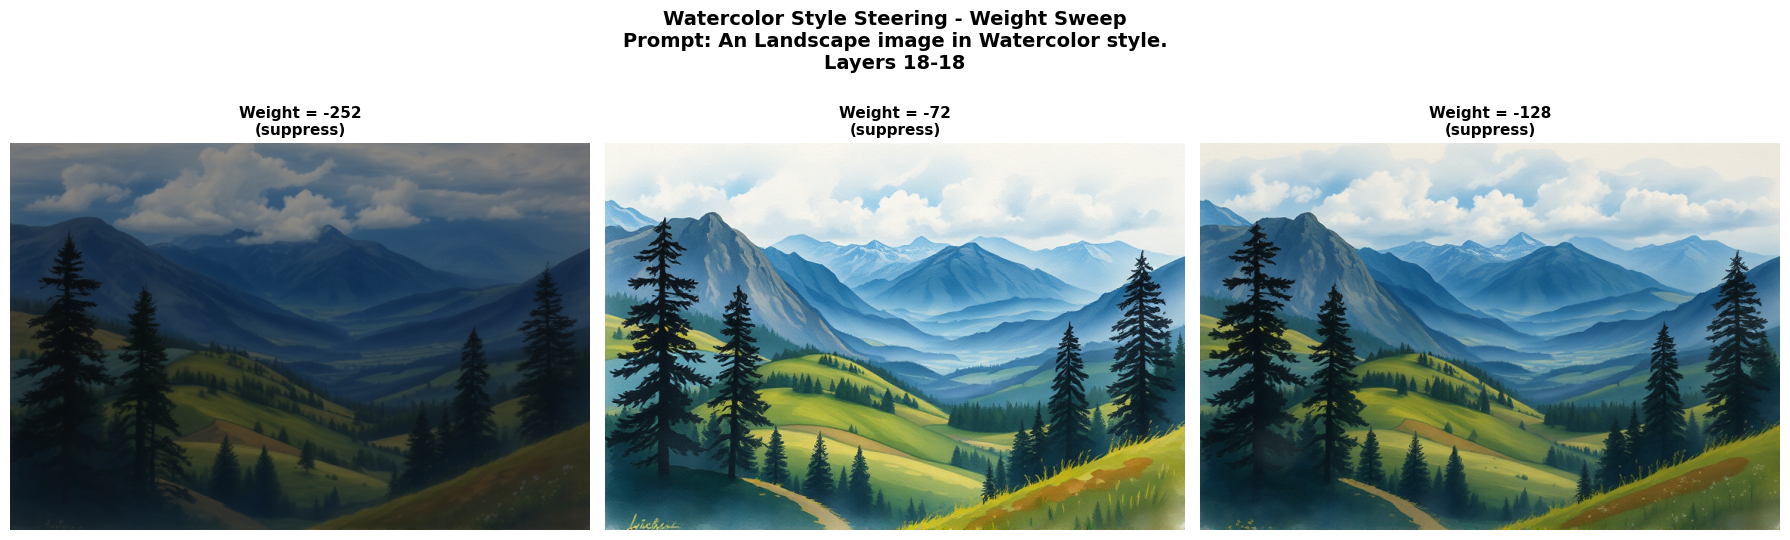


✅ Visualization saved: Watercolor_Landscape_weight_sweep.png

💡 Interpretation:
  • Negative weights: Suppress the style (steer AWAY from style)
  • Weight = 0: No steering (baseline)
  • Positive weights: Enhance the style (steer TOWARDS style)
  • Larger magnitudes: Stronger effect


In [ ]:
# ============================================================================
# Weight Sweep: Test Multiple Steering Strengths
# ============================================================================

print("\n🎨 Generating steered images with weight sweep...")
print(f"Steering layers: {START_LAYER} to {END_LAYER}")

# Define weight sweep range
# Negative weights = suppress style, Positive = enhance style
# WEIGHTS = [-4, -5, -6, -6, -8, -10, -12 ]
WEIGHTS = [-252, -72, -128]
# WEIGHTS = [-36, -48, -52]
# Steering settings
START_LAYER = 18 # Start applying steering from this layer
END_LAYER = 18    # End applying steering at this layer

# Try to load from cache first
CONCEPT_NAME = f"{style}_{object_class}_suppress"
layer_vectors = vector_cache.load_layer_range(
    concept=CONCEPT_NAME,
    start_layer=START_LAYER,
    end_layer=END_LAYER,
    stream="both"
)


print(f"Weight sweep: {WEIGHTS}")
print(f"Total images to generate: {len(WEIGHTS)}")

steered_images = {}

for weight in tqdm(WEIGHTS, desc="Weight sweep"):
    print(f"\n  Generating with weight={weight}...")

    # Use same seed for all weights to isolate the effect of steering
    generator = torch.Generator(device='cuda').manual_seed(SEED)

    # Pass dict of layer-specific vectors
    steered_image, stats = generate_steered_image(
        pipe=pipe,
        generator=generator,
        prompt=prompt,
        start_layer=START_LAYER,
        end_layer=END_LAYER,
        weight=weight,
        steering_vector=layer_vectors,  # Dict: {layer_idx: vector}
        height=HEIGHT,
        width=WIDTH,
        inference_steps=NUM_INFERENCE_STEPS,
        steer_target=STREAM
    )

    # Save steered image
    filename = f"{style}_{object_class}_steered_w{int(weight):+g}.png"
    steered_image.save(filename)
    steered_images[weight] = steered_image
    print(f"  ✅ Saved: {filename}")

print(f"\n✅ Generated {len(steered_images)} steered images!")

# ============================================================================
# Display Results Grid
# ============================================================================

print("\n📊 Displaying results...")

import matplotlib.pyplot as plt
import numpy as np

# Calculate grid size
n_images = len(WEIGHTS)
cols = 3
rows = (n_images + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 6*rows))
axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

# Show steered images
for idx, weight in enumerate(WEIGHTS):
    if idx < len(axes):
        axes[idx].imshow(steered_images[weight])
        direction = "suppress" if weight < 0 else "enhance" if weight > 0 else "no steering"
        axes[idx].set_title(f"Weight = {weight:+g}\n({direction})", fontsize=11, fontweight='bold')
        axes[idx].axis('off')

# Hide unused subplots
for idx in range(n_images, len(axes)):
    axes[idx].axis('off')

plt.suptitle(f"{style} Style Steering - Weight Sweep\nPrompt: {prompt}\nLayers {START_LAYER}-{END_LAYER}",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{style}_{object_class}_weight_sweep.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Visualization saved: {style}_{object_class}_weight_sweep.png")
print("\n💡 Interpretation:")
print("  • Negative weights: Suppress the style (steer AWAY from style)")
print("  • Weight = 0: No steering (baseline)")
print("  • Positive weights: Enhance the style (steer TOWARDS style)")
print("  • Larger magnitudes: Stronger effect")


In [ ]:
# ============================================================================
# Setup for ViT Classifier
# (Only run this once - needed for classifier to work)
# ============================================================================

import timm
from torchvision import transforms

# Why do we need all these styles if we're only testing one?
# Answer: The classifier was TRAINED on all 50/60 styles, so it outputs
# probabilities for ALL styles. This list just converts output index → name.
# e.g., If classifier outputs index 45, we look up theme_available[45] = "Van_Gogh"

theme_available = ["Abstractionism", "Artist_Sketch", "Blossom_Season", "Blue_Blooming", "Bricks", "Byzantine",
    "Cartoon", "Cold_Warm", "Color_Fantasy", "Comic_Etch", "Crayon", "Crypto_Punks", "Cubism", "Dadaism", "Dapple",
    "Defoliation", "Dreamweave", "Early_Autumn", "Expressionism", "Fauvism", "Foliage_Patchwork", "French",
    "Glowing_Sunset", "Gorgeous_Love", "Greenfield", "Impasto", "Impressionism", "Ink_Art", "Joy", "Liquid_Dreams",
    "Palette_Knife", "Magic_Cube", "Meta_Physics", "Meteor_Shower", "Monet", "Mosaic", "Neon_Lines", "On_Fire",
    "Pastel", "Pencil_Drawing", "Picasso", "Pointillism", "Pop_Art", "Rainwash", "Realistic_Watercolor", "Red_Blue_Ink",
    "Rust", "Seed_Images", "Sketch", "Sponge_Dabbed", "Structuralism", "Superstring", "Surrealism", "Techno", "Ukiyoe",
    "Van_Gogh", "Vibrant_Flow", "Warm_Love", "Warm_Smear", "Watercolor", "Winter"]


print(f"✅ Loaded {len(theme_available)} style names (for classifier output mapping)")
print(f"   Your target style '{style}' is at index {theme_available.index(style)}")


✅ Loaded 61 style names (for classifier output mapping)
   Your target style 'Sketch' is at index 48


In [ ]:
# ============================================================================
# Load the ViT-Large Classifier Checkpoint
# ============================================================================

# Path to your downloaded checkpoint
CHECKPOINT_PATH = "Unlearning_Canvas/style60.pth"
# Or use: "UnlearnCanvas/ckpts/cls_model/style50.pth"

print(f"Loading ViT-Large classifier from: {CHECKPOINT_PATH}")

# Load checkpoint to detect number of classes
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)

# Detect number of classes from checkpoint
if "head.weight" in checkpoint["model_state_dict"]:
    num_classes = checkpoint["model_state_dict"]["head.weight"].shape[0]
    print(f"Detected {num_classes} classes in checkpoint")

    if num_classes == 60:
        print("→ Using 60-style version")
    elif num_classes == 50:
        print("→ Using 50-style version")
else:
    num_classes = 50  # Default

# Create ViT-Large model
vit_model = timm.create_model("vit_large_patch16_224.augreg_in21k", pretrained=True).to(DEVICE)

# Replace classification head with correct size
vit_model.head = torch.nn.Linear(1024, num_classes).to(DEVICE)

# Load the fine-tuned weights
vit_model.load_state_dict(checkpoint["model_state_dict"])
vit_model.eval()

print(f"✅ ViT classifier loaded successfully!")
print(f"   Model: ViT-Large")
print(f"   Classes: {num_classes} styles")
print(f"   Device: {DEVICE}")

Loading ViT-Large classifier from: Unlearning_Canvas/style60.pth
Detected 61 classes in checkpoint


model.safetensors:   0%|          | 0.00/1.30G [00:00<?, ?B/s]

✅ ViT classifier loaded successfully!
   Model: ViT-Large
   Classes: 61 styles
   Device: cuda


In [ ]:
# ============================================================================
# Classify Both Images (Baseline vs Steered)
# ============================================================================

# Preprocessing transform (official UnlearnCanvas format)
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

def classify_image(image, model, device):
    """Classify a PIL image using ViT classifier"""
    # Preprocess
    img_tensor = image_transform(image.convert('RGB')).unsqueeze(0).to(device)

    # Inference
    with torch.no_grad():
        logits = model(img_tensor)
        probs = torch.softmax(logits, dim=1)

        # Top prediction
        top_prob, top_idx = torch.max(probs, dim=1)
        top_style = theme_available[top_idx.item()]

        # Top-5 predictions
        top5_probs, top5_indices = torch.topk(probs[0], k=min(5, len(theme_available)))
        top5_styles = [theme_available[idx] for idx in top5_indices.cpu().numpy()]
        top5_confidences = top5_probs.cpu().numpy()

    return {
        'predicted_style': top_style,
        'confidence': top_prob.item(),
        'top5_styles': top5_styles,
        'top5_confidences': top5_confidences,
        'all_probs': probs[0].cpu().numpy()
    }

print("🔍 Classifying images...\n")

# Classify baseline image
baseline_result = classify_image(baseline_image, vit_model, DEVICE)

# Classify steered image
steered_result = classify_image(steered_image, vit_model, DEVICE)

print("="*70)
print("📊 CLASSIFICATION RESULTS")
print("="*70)

print(f"\n🖼️  BASELINE IMAGE (No Steering):")
print(f"   Predicted Style: {baseline_result['predicted_style']}")
print(f"   Confidence: {baseline_result['confidence']:.2%}")
print(f"\n   Top-5 Predictions:")
for i, (style_name, conf) in enumerate(zip(baseline_result['top5_styles'],
                                           baseline_result['top5_confidences']), 1):
    bar = "█" * int(conf * 50)
    print(f"   {i}. {style_name:20s} {conf:.4f} ({conf*100:.2f}%) {bar}")

print(f"\n🎨 STEERED IMAGE (Weight={WEIGHT}):")
print(f"   Predicted Style: {steered_result['predicted_style']}")
print(f"   Confidence: {steered_result['confidence']:.2%}")
print(f"\n   Top-5 Predictions:")
for i, (style_name, conf) in enumerate(zip(steered_result['top5_styles'],
                                           steered_result['top5_confidences']), 1):
    bar = "█" * int(conf * 50)
    print(f"   {i}. {style_name:20s} {conf:.4f} ({conf*100:.2f}%) {bar}")

print("\n" + "="*70)


🔍 Classifying images...

📊 CLASSIFICATION RESULTS

🖼️  BASELINE IMAGE (No Steering):
   Predicted Style: Sketch
   Confidence: 99.81%

   Top-5 Predictions:
   1. Sketch               0.9981 (99.81%) █████████████████████████████████████████████████
   2. Seed_Images          0.0004 (0.04%) 
   3. Cartoon              0.0003 (0.03%) 
   4. Ink_Art              0.0002 (0.02%) 
   5. Artist_Sketch        0.0001 (0.01%) 

🎨 STEERED IMAGE (Weight=-16):
   Predicted Style: Seed_Images
   Confidence: 100.00%

   Top-5 Predictions:
   1. Seed_Images          1.0000 (100.00%) █████████████████████████████████████████████████
   2. Sketch               0.0000 (0.00%) 
   3. Warm_Love            0.0000 (0.00%) 
   4. Glowing_Sunset       0.0000 (0.00%) 
   5. Pop_Art              0.0000 (0.00%) 



In [ ]:
# ============================================================================
# Evaluate Suppression Effectiveness
# ============================================================================

print("🎯 SUPPRESSION EVALUATION")
print("="*70)

target_style = style  # The style we tried to suppress
target_idx = theme_available.index(target_style)

# Check baseline
baseline_predicted_idx = theme_available.index(baseline_result['predicted_style'])
baseline_is_target = (baseline_predicted_idx == target_idx)

# Check steered
steered_predicted_idx = theme_available.index(steered_result['predicted_style'])
steered_is_target = (steered_predicted_idx == target_idx)

print(f"\nTarget Style to Suppress: {target_style}")
print(f"Steering Weight: {WEIGHT}")

print(f"\n📊 Results:")
print(f"   Baseline → Predicted: {baseline_result['predicted_style']}")
print(f"              Matches target? {'✅ YES' if baseline_is_target else '❌ NO'}")
print(f"              Confidence: {baseline_result['confidence']:.2%}")

print(f"\n   Steered  → Predicted: {steered_result['predicted_style']}")
print(f"              Matches target? {'❌ YES (suppression failed)' if steered_is_target else '✅ NO (suppression worked!)'}")
print(f"              Confidence: {steered_result['confidence']:.2%}")

# Calculate suppression success
if baseline_is_target and not steered_is_target:
    print(f"\n🎉 SUCCESS! Style successfully suppressed!")
    print(f"   Before: Classified as {target_style} ({baseline_result['confidence']:.1%})")
    print(f"   After:  Classified as {steered_result['predicted_style']} ({steered_result['confidence']:.1%})")
elif baseline_is_target and steered_is_target:
    print(f"\n⚠️  PARTIAL: Baseline was {target_style}, steered still {target_style}")
    print(f"   Try stronger suppression weight (more negative)")
    print(f"   Current weight: {WEIGHT}, try: {WEIGHT * 2}")
elif not baseline_is_target:
    print(f"\n❓ BASELINE ISSUE: Baseline wasn't classified as {target_style}")
    print(f"   Baseline was: {baseline_result['predicted_style']}")
    print(f"   Steered is:   {steered_result['predicted_style']}")

# Show probability change for target style
baseline_target_prob = baseline_result['all_probs'][target_idx]
steered_target_prob = steered_result['all_probs'][target_idx]
prob_decrease = baseline_target_prob - steered_target_prob

print(f"\n📉 Probability Change for {target_style}:")
print(f"   Baseline: {baseline_target_prob:.4f} ({baseline_target_prob*100:.2f}%)")
print(f"   Steered:  {steered_target_prob:.4f} ({steered_target_prob*100:.2f}%)")
print(f"   Decrease: {prob_decrease:.4f} ({prob_decrease*100:.2f} percentage points)")

if prob_decrease > 0:
    print(f"   ✅ Probability decreased (good for suppression)")
else:
    print(f"   ⚠️  Probability increased or stayed same")

print("\n" + "="*70)

🎯 SUPPRESSION EVALUATION

Target Style to Suppress: Sketch
Steering Weight: -16

📊 Results:
   Baseline → Predicted: Sketch
              Matches target? ✅ YES
              Confidence: 99.81%

   Steered  → Predicted: Seed_Images
              Matches target? ✅ NO (suppression worked!)
              Confidence: 100.00%

🎉 SUCCESS! Style successfully suppressed!
   Before: Classified as Sketch (99.8%)
   After:  Classified as Seed_Images (100.0%)

📉 Probability Change for Sketch:
   Baseline: 0.9981 (99.81%)
   Steered:  0.0000 (0.00%)
   Decrease: 0.9980 (99.80 percentage points)
   ✅ Probability decreased (good for suppression)



In [ ]:
# ============================================================================
# MULTI-LAYER WEIGHT SWEEP: Test Different Extraction Layers
# ============================================================================
import matplotlib.pyplot as plt
import numpy as np

# Configuration
TEST_LAYERS = [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]  # Layers to test
WEIGHT_SWEEP = [-16, -32, -64, -128, -150, -256, -512]  # Weights to test
NUM_SEEDS_FOR_AVERAGING = 5  # Number of seeds to average over
SHOW_BASELINE = True  # Include baseline in visualization

print(f"{'='*70}")
print(f"MULTI-LAYER WEIGHT SWEEP")
print(f"{'='*70}")
print(f"Testing layers: {TEST_LAYERS}")
print(f"Weight sweep: {WEIGHT_SWEEP}")
print(f"Stream: {STREAM}")
print(f"Averaging over: {NUM_SEEDS_FOR_AVERAGING} seeds\n")

# Generate seed list (same for all layers for consistency)
import random
random.seed(SEED)
seed_list = [random.randint(0, 999999) for _ in range(NUM_SEEDS_FOR_AVERAGING)]

# For each layer, run the weight sweep
for layer_idx, test_layer in enumerate(TEST_LAYERS, 1):
    print(f"\n{'='*70}")
    print(f"LAYER {test_layer} ({layer_idx}/{len(TEST_LAYERS)})")
    print(f"{'='*70}\n")

    # Step 1: Create steering vector for this layer (averaged over seeds)
    print(f"🧭 Creating averaged steering vector for layer {test_layer}...")
    vectors_to_average = []

    for seed_val in seed_list:
        vector = contrastive_steering_vector(
            transformer=pipe.transformer,
            layer_indices=test_layer,
            pos_prompt=pos_prompt,
            neg_prompt=neg_prompt,
            pipe=pipe,
            stream=STREAM,
            steps=NUM_INFERENCE_STEPS,
            H=HEIGHT,
            W=WIDTH,
            seed=seed_val
        )
        vectors_to_average.append(vector)

    # Average the vectors
    image_vecs = [v['image'] for v in vectors_to_average if v is not None and 'image' in v]
    text_vecs = [v['text'] for v in vectors_to_average if v is not None and 'text' in v]

    steering_vector = {
        'image': torch.stack(image_vecs).mean(dim=0),
        'text': torch.stack(text_vecs).mean(dim=0)
    }

    print(f"  Vector norms: img={steering_vector['image'].norm():.3f}, txt={steering_vector['text'].norm():.3f}")
    print(f"✅ Steering vector created\n")

    # Step 2: Generate images for weight sweep
    print(f"🎨 Generating steered images for weight sweep...")
    results = {}

    # Optionally include baseline
    if SHOW_BASELINE:
        weights_to_test = [0] + WEIGHT_SWEEP
    else:
        weights_to_test = WEIGHT_SWEEP

    for weight in weights_to_test:
        # Create fresh generator for each image
        generator = torch.Generator(device='cuda').manual_seed(SEED)

        steered_image, stats = generate_steered_image(
            pipe=pipe,
            generator=generator,
            prompt=prompt,
            start_layer=test_layer,
            end_layer=test_layer,
            weight=float(weight),
            steering_vector=steering_vector,
            height=HEIGHT,
            width=WIDTH,
            inference_steps=NUM_INFERENCE_STEPS,
            steer_target=STREAM
        )

        results[weight] = {'image': steered_image}

    print(f"✅ Generated {len(results)} images\n")

    # Step 3: Visualize results for this layer
    print(f"📊 Creating visualization for layer {test_layer}...\n")

    num_images = len(results)
    cols = min(4, num_images)
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
    if rows == 1 and cols == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = axes.reshape(1, -1)
    elif cols == 1:
        axes = axes.reshape(-1, 1)

    for idx, weight in enumerate(weights_to_test):
        row = idx // cols
        col = idx % cols
        ax = axes[row, col]

        # Display image
        ax.imshow(results[weight]['image'])

        # Create title
        if weight == 0:
            title = f"Weight = 0 (Baseline)"
        else:
            title = f"Weight = {weight}"

        ax.set_title(title, fontsize=12)
        ax.axis('off')

    # Hide empty subplots
    for idx in range(len(results), rows * cols):
        row = idx // cols
        col = idx % cols
        axes[row, col].axis('off')

    plt.suptitle(f"Layer {test_layer} - Weight Sweep for {style} Style Suppression",
                 fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

    print(f"✅ Layer {test_layer} complete!\n")

print(f"{'='*70}")
print(f"✅ All layers tested!")
print(f"{'='*70}")

Output hidden; open in https://colab.research.google.com to view.

EXACT RECONSTRUCTION TEST: Activation Difference Injection

🔍 Detecting available layers...
   Found 57 layers in the model ✓
   - Double-stream: 19 layers (0-18)
   - Single-stream: 38 layers (19-56)

Styled prompt:   'An image of Flowers in Van_Gogh style.'
Unstyled prompt: 'An image of Flowers.'
Seed: 42
Testing layers: 0 to 56 (ALL layers)

🎨 Step 1: Capturing activations...
  This will capture 57 layers × 2 generations...
  (Estimated time: ~30-60 seconds)

  Generating styled image (A)...


  0%|          | 0/4 [00:00<?, ?it/s]

     Done in 4.9s
  Generating unstyled image (B)...


  0%|          | 0/4 [00:00<?, ?it/s]

     Done in 2.8s

✅ Captured activations from 57 layers (total time: 7.7s)

📊 Activation details:
  Example layer 10:
    Image stream: torch.Size([1, 1536, 3072])
    Text stream:  torch.Size([1, 512, 3072])

  Note: Shape is [Batch, Tokens, Channels] - TOKEN structure is PRESERVED!
        (No averaging over the 1536 tokens)
        Each token represents a spatial region of the image

💾 Memory usage: 2736.0 MB (2.67 GB) for 57 layers × 2 generations

🔢 Step 2: Computing activation differences...
✅ Computed differences for 57 layers
   Double-stream: 19 layers (0-18)
   Single-stream: 38 layers (19-56)

📈 Difference statistics (sampling first, middle, last layers):

  Layer 0:
    Image diff - mean: 0.008667, std: 1.187500, max: 29.000000
    Text diff  - mean: -0.009521, std: 1.078125, max: 364.000000

  Layer 28:
    Image diff - mean: 0.064453, std: 28.000000, max: 29952.000000
    Text diff  - mean: 0.111328, std: 460.000000, max: 226304.000000

  Layer 56:
    Image diff - mean:

  0%|          | 0/4 [00:00<?, ?it/s]

✅ Reconstruction complete! (took 2.4s)

📊 Step 4: Comparing results...

🎯 Reconstruction Quality:
  Original A vs B:
    Mean pixel diff: 60.507366
    Max pixel diff:  255.000000

  Target B vs Reconstructed:
    Mean pixel diff: 69.589828
    Max pixel diff:  255.000000

⚠️  Reconstruction has some error (this is expected due to stochastic layers)
   Reconstruction error: 27.29%

🖼️  Visualizing results...


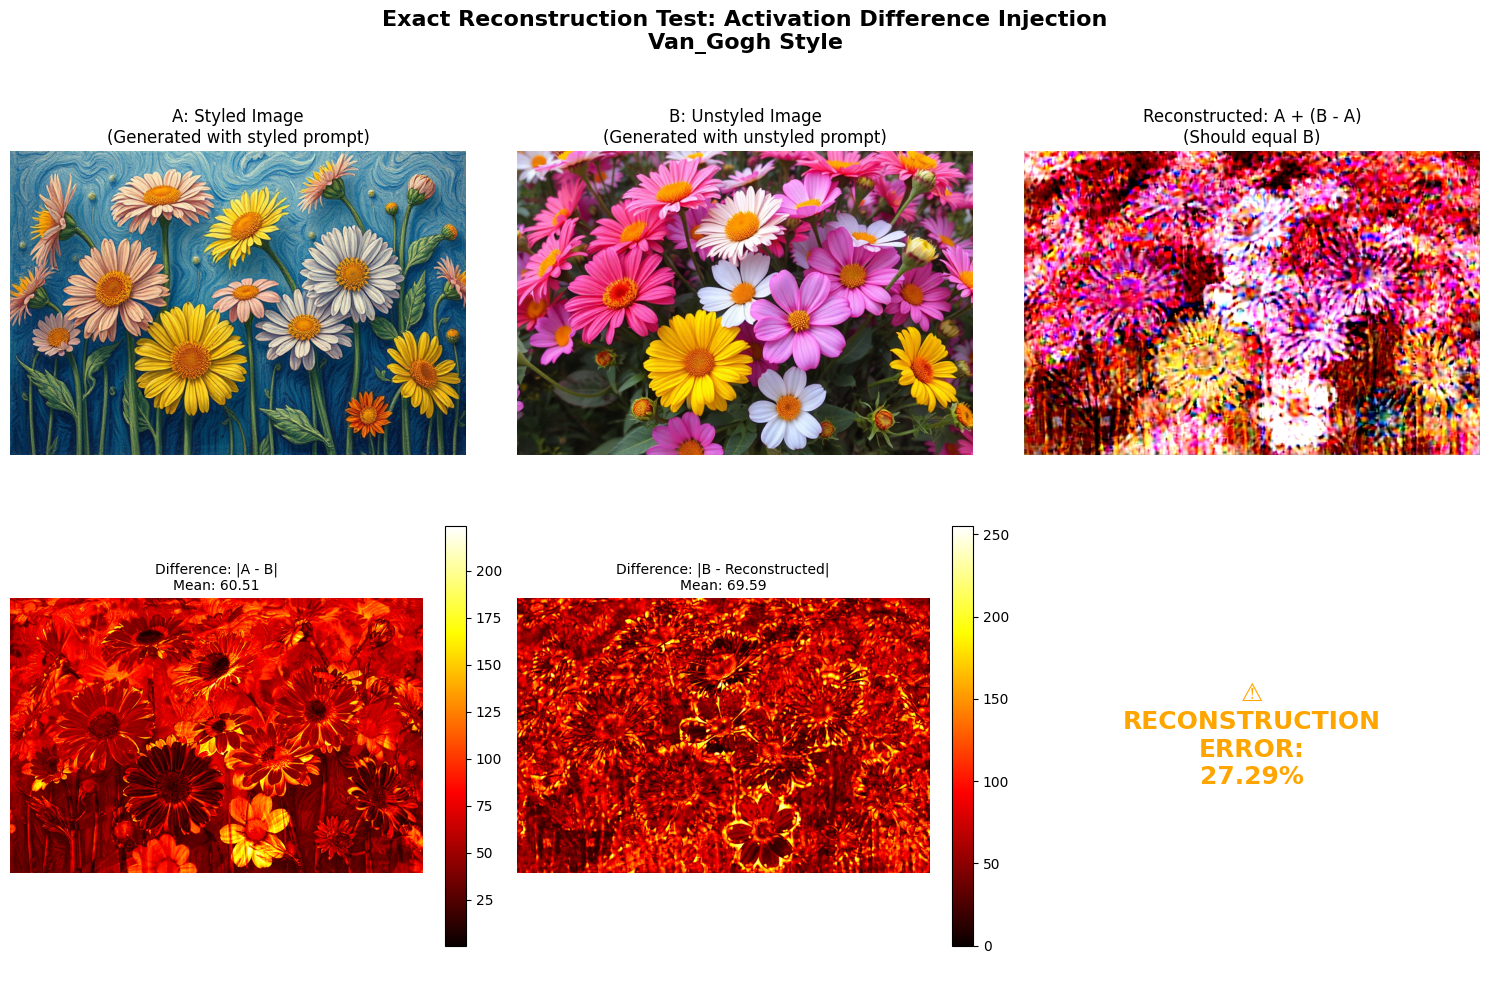


SUMMARY
✓ Tested ALL 57 layers (including single-stream layers)
✓ Captured full token activations (no averaging) for both generations
✓ Computed per-token activation differences: B - A
✓ Re-injected differences into styled generation
✓ Reconstruction error: 69.5898 / 255.0 = 27.29%

⚠️  Similar to 19-layer baseline (65.48 vs 69.59)
   → Style information is mostly in early layers (0-18)

💡 Next steps:
   - Run the Analysis cell (Cell 13) to see which layers matter most
   - Check if token averaging loses important information
   - Identify optimal layers for steering based on difference magnitudes


In [ ]:
# ============================================================================
# EXACT RECONSTRUCTION TEST - Activation Difference Injection
# ============================================================================
# This implements the proposed approach:
# 1. Generate A (styled) and B (unstyled) with SAME seed
# 2. Capture FULL activations (no spatial averaging) at each layer
# 3. Compute difference: diff = B - A (keeping spatial structure)
# 4. Re-inject: A + diff → should exactly reproduce B

import torch
from flux_steering.hook_utils import get_layer
from contextlib import contextmanager

print("="*70)
print("EXACT RECONSTRUCTION TEST: Activation Difference Injection")
print("="*70)

object_class = "Flowers"
style = "Van_Gogh"

# Configuration
SEED = 42
TEST_PROMPT_STYLED = f"An image of {object_class} in {style} style."
TEST_PROMPT_UNSTYLED = f"An image of {object_class}."

# Auto-detect all available layers
print("\n🔍 Detecting available layers...")

# Get directly from config (most reliable method)
cfg = pipe.transformer.config
num_double = getattr(cfg, "num_layers", 19)
num_single = getattr(cfg, "num_single_layers", 38)
total_layers = num_double + num_single

# Verify the last layer is accessible
try:
    get_layer(pipe.transformer, total_layers - 1)
    print(f"   Found {total_layers} layers in the model ✓")
    print(f"   - Double-stream: {num_double} layers (0-{num_double-1})")
    print(f"   - Single-stream: {num_single} layers ({num_double}-{total_layers-1})")
except Exception as e:
    print(f"   ⚠️  Config says {total_layers} layers but verification failed: {e}")
    # Fall back to scanning with SPECIFIC exception handling
    total_layers = 0
    for i in range(100):
        try:
            get_layer(pipe.transformer, i)
            total_layers = i + 1
        except (IndexError, AttributeError):  # Only catch expected errors!
            break
    print(f"   Detected {total_layers} layers by scanning")

TEST_LAYERS = list(range(total_layers))

print(f"\nStyled prompt:   '{TEST_PROMPT_STYLED}'")
print(f"Unstyled prompt: '{TEST_PROMPT_UNSTYLED}'")
print(f"Seed: {SEED}")
print(f"Testing layers: {TEST_LAYERS[0]} to {TEST_LAYERS[-1]} (ALL layers)")

# ============================================================================
# Step 1: Capture full activations (NO spatial averaging)
# ============================================================================

def capture_full_activations(pipe, prompt, layers_to_capture, seed, height=512, width=768, steps=4):
    """
    Capture FULL activation maps (with token structure intact, no averaging).

    Works with both double-stream (layers 0-18) and single-stream layers (19+).

    Returns:
        dict[layer_idx] = {
            'image': torch.Tensor [B, Tokens, Channels],  # All image tokens
            'text': torch.Tensor [B, Tokens, Channels]    # All text tokens (or zeros for single-stream)
        }
    """
    activations = {}

    def make_capture_hook(layer_id):
        def hook(module, inputs, output):
            # Double-stream output: (text_stream, image_stream)
            if isinstance(output, tuple) and len(output) == 2:
                text_h, image_h = output
                activations[layer_id] = {
                    'text': text_h.detach().cpu().clone(),   # [B, T, D] - keep all tokens
                    'image': image_h.detach().cpu().clone()  # [B, Tokens, D] - keep all tokens!
                }
            else:
                # Single-stream (treat as image-only)
                # Create zero tensor for text stream to maintain consistency
                img_output = output.detach().cpu().clone()
                activations[layer_id] = {
                    'text': torch.zeros_like(img_output),  # Dummy zeros for consistency
                    'image': img_output
                }
            return output
        return hook

    # Register hooks
    handles = []
    try:
        for layer_idx in layers_to_capture:
            _, mod, _ = get_layer(pipe.transformer, layer_idx)
            handles.append(mod.register_forward_hook(make_capture_hook(layer_idx)))

        # Generate image
        generator = torch.Generator(device='cuda').manual_seed(seed)
        image = pipe(
            prompt=prompt,
            height=height,
            width=width,
            num_inference_steps=steps,
            guidance_scale=0.0,
            generator=generator,
        ).images[0]

    finally:
        for h in handles:
            try:
                h.remove()
            except:
                pass

    return image, activations

print("\n🎨 Step 1: Capturing activations...")
print(f"  This will capture {len(TEST_LAYERS)} layers × 2 generations...")
print(f"  (Estimated time: ~30-60 seconds)")

import time
start_time = time.time()

print("\n  Generating styled image (A)...")
image_A, activations_A = capture_full_activations(
    pipe, TEST_PROMPT_STYLED, TEST_LAYERS, SEED, HEIGHT, WIDTH, NUM_INFERENCE_STEPS
)
print(f"     Done in {time.time() - start_time:.1f}s")

mid_time = time.time()
print("  Generating unstyled image (B)...")
image_B, activations_B = capture_full_activations(
    pipe, TEST_PROMPT_UNSTYLED, TEST_LAYERS, SEED, HEIGHT, WIDTH, NUM_INFERENCE_STEPS
)
print(f"     Done in {time.time() - mid_time:.1f}s")

print(f"\n✅ Captured activations from {len(activations_A)} layers (total time: {time.time() - start_time:.1f}s)")

# Show shapes and memory usage
sample_layer = TEST_LAYERS[min(10, len(TEST_LAYERS)-1)]
print(f"\n📊 Activation details:")
print(f"  Example layer {sample_layer}:")
print(f"    Image stream: {activations_A[sample_layer]['image'].shape}")
print(f"    Text stream:  {activations_A[sample_layer]['text'].shape}")
print(f"\n  Note: Shape is [Batch, Tokens, Channels] - TOKEN structure is PRESERVED!")
print(f"        (No averaging over the {activations_A[sample_layer]['image'].shape[1]} tokens)")
print(f"        Each token represents a spatial region of the image")

# Calculate memory usage
total_elements = 0
for layer_idx in TEST_LAYERS:
    total_elements += activations_A[layer_idx]['image'].numel()
    total_elements += activations_A[layer_idx]['text'].numel()
    total_elements += activations_B[layer_idx]['image'].numel()
    total_elements += activations_B[layer_idx]['text'].numel()

memory_mb = (total_elements * 4) / (1024**2)  # float32 = 4 bytes
print(f"\n💾 Memory usage: {memory_mb:.1f} MB ({memory_mb/1024:.2f} GB) for {len(TEST_LAYERS)} layers × 2 generations")

# ============================================================================
# Step 2: Compute activation differences
# ============================================================================

print(f"\n🔢 Step 2: Computing activation differences...")
activation_diffs = {}

for layer_idx in TEST_LAYERS:
    activation_diffs[layer_idx] = {
        'image': activations_B[layer_idx]['image'] - activations_A[layer_idx]['image'],
        'text': activations_B[layer_idx]['text'] - activations_A[layer_idx]['text']
    }

print(f"✅ Computed differences for {len(activation_diffs)} layers")

# Check for any issues
double_stream_layers = [i for i in TEST_LAYERS if i < 19]
single_stream_layers = [i for i in TEST_LAYERS if i >= 19]
print(f"   Double-stream: {len(double_stream_layers)} layers (0-{double_stream_layers[-1]})")
print(f"   Single-stream: {len(single_stream_layers)} layers ({single_stream_layers[0]}-{single_stream_layers[-1]})")

# Analyze difference statistics
print(f"\n📈 Difference statistics (sampling first, middle, last layers):")
# Sample layers: first, middle, and last
num_layers = len(TEST_LAYERS)
sample_layer_indices = [0, num_layers // 2, num_layers - 1]
for layer_idx in sample_layer_indices:
    img_diff = activation_diffs[layer_idx]['image']
    txt_diff = activation_diffs[layer_idx]['text']

    print(f"\n  Layer {layer_idx}:")
    print(f"    Image diff - mean: {img_diff.mean():.6f}, std: {img_diff.std():.6f}, max: {img_diff.abs().max():.6f}")
    print(f"    Text diff  - mean: {txt_diff.mean():.6f}, std: {txt_diff.std():.6f}, max: {txt_diff.abs().max():.6f}")

# ============================================================================
# Step 3: Re-inject differences to verify exact reconstruction
# ============================================================================

print(f"\n🔬 Step 3: Testing exact reconstruction...")
print(f"  Theory: If we inject (B - A) into generation A, we should get exactly B")
print(f"  Injecting into all {len(TEST_LAYERS)} layers...")

def generate_with_activation_injection(pipe, prompt, injection_diffs, seed, height=512, width=768, steps=4):
    """
    Generate image while injecting pre-computed activation differences.

    This modifies activations during generation:
        activation_new = activation_original + injection_diff
    """

    def make_injection_hook(layer_id):
        def hook(module, inputs, output):
            if isinstance(output, tuple) and len(output) == 2:
                # Double-stream layer
                text_h, image_h = output

                # Inject the differences
                diff = injection_diffs[layer_id]
                image_h_new = image_h + diff['image'].to(image_h.device, image_h.dtype)
                text_h_new = text_h + diff['text'].to(text_h.device, text_h.dtype)

                return (text_h_new, image_h_new)
            else:
                # Single-stream layer (image-only)
                diff = injection_diffs[layer_id]
                # Only inject image difference (text diff should be zeros for single-stream)
                return output + diff['image'].to(output.device, output.dtype)
        return hook

    # Register injection hooks
    handles = []
    try:
        for layer_idx in injection_diffs.keys():
            _, mod, _ = get_layer(pipe.transformer, layer_idx)
            handles.append(mod.register_forward_hook(make_injection_hook(layer_idx)))

        # Generate image with injection
        generator = torch.Generator(device='cuda').manual_seed(seed)
        image = pipe(
            prompt=prompt,
            height=height,
            width=width,
            num_inference_steps=steps,
            guidance_scale=0.0,
            generator=generator,
        ).images[0]

    finally:
        for h in handles:
            try:
                h.remove()
            except:
                pass

    return image

print("\n  Generating: A + (B - A) = ?")
recon_start = time.time()
image_reconstructed = generate_with_activation_injection(
    pipe, TEST_PROMPT_STYLED, activation_diffs, SEED, HEIGHT, WIDTH, NUM_INFERENCE_STEPS
)

print(f"✅ Reconstruction complete! (took {time.time() - recon_start:.1f}s)")

# ============================================================================
# Step 4: Compare results
# ============================================================================

print(f"\n📊 Step 4: Comparing results...")

# Convert images to tensors for comparison
import numpy as np
from PIL import Image

def pil_to_tensor(img):
    return torch.from_numpy(np.array(img)).float()

tensor_A = pil_to_tensor(image_A)
tensor_B = pil_to_tensor(image_B)
tensor_reconstructed = pil_to_tensor(image_reconstructed)

# Compute pixel-wise differences
diff_B_vs_reconstructed = (tensor_B - tensor_reconstructed).abs()
diff_A_vs_B = (tensor_A - tensor_B).abs()

print(f"\n🎯 Reconstruction Quality:")
print(f"  Original A vs B:")
print(f"    Mean pixel diff: {diff_A_vs_B.mean():.6f}")
print(f"    Max pixel diff:  {diff_A_vs_B.max():.6f}")
print(f"\n  Target B vs Reconstructed:")
print(f"    Mean pixel diff: {diff_B_vs_reconstructed.mean():.6f}")
print(f"    Max pixel diff:  {diff_B_vs_reconstructed.max():.6f}")

# Check if reconstruction is exact
if diff_B_vs_reconstructed.max() < 1.0:  # Within 1 pixel value (0-255 scale)
    print(f"\n✅ SUCCESS! Exact reconstruction achieved!")
    print(f"   The activation differences perfectly capture the style transformation!")
else:
    reconstruction_error_pct = (diff_B_vs_reconstructed.mean() / 255.0) * 100
    print(f"\n⚠️  Reconstruction has some error (this is expected due to stochastic layers)")
    print(f"   Reconstruction error: {reconstruction_error_pct:.2f}%")

# ============================================================================
# Step 5: Visualize
# ============================================================================

print(f"\n🖼️  Visualizing results...")

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Row 1: Images
axes[0, 0].imshow(image_A)
axes[0, 0].set_title("A: Styled Image\n(Generated with styled prompt)", fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(image_B)
axes[0, 1].set_title("B: Unstyled Image\n(Generated with unstyled prompt)", fontsize=12)
axes[0, 1].axis('off')

axes[0, 2].imshow(image_reconstructed)
axes[0, 2].set_title("Reconstructed: A + (B - A)\n(Should equal B)", fontsize=12)
axes[0, 2].axis('off')

# Row 2: Difference maps
diff_AB_vis = diff_A_vs_B.numpy().mean(axis=2)  # Average over RGB
diff_B_recon_vis = diff_B_vs_reconstructed.numpy().mean(axis=2)

im1 = axes[1, 0].imshow(diff_AB_vis, cmap='hot')
axes[1, 0].set_title(f"Difference: |A - B|\nMean: {diff_A_vs_B.mean():.2f}", fontsize=10)
axes[1, 0].axis('off')
plt.colorbar(im1, ax=axes[1, 0], fraction=0.046)

im2 = axes[1, 1].imshow(diff_B_recon_vis, cmap='hot')
axes[1, 1].set_title(f"Difference: |B - Reconstructed|\nMean: {diff_B_vs_reconstructed.mean():.2f}", fontsize=10)
axes[1, 1].axis('off')
plt.colorbar(im2, ax=axes[1, 1], fraction=0.046)

# Success indicator
if diff_B_vs_reconstructed.max() < 1.0:
    axes[1, 2].text(0.5, 0.5, "✅\nEXACT\nRECONSTRUCTION!",
                    ha='center', va='center', fontsize=24, color='green', weight='bold')
else:
    error_pct = (diff_B_vs_reconstructed.mean() / 255.0) * 100
    axes[1, 2].text(0.5, 0.5, f"⚠️\nRECONSTRUCTION\nERROR:\n{error_pct:.2f}%",
                    ha='center', va='center', fontsize=18, color='orange', weight='bold')
axes[1, 2].axis('off')

plt.suptitle(f"Exact Reconstruction Test: Activation Difference Injection\n{style} Style",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("SUMMARY")
print("="*70)
print(f"✓ Tested ALL {len(TEST_LAYERS)} layers (including single-stream layers)")
print(f"✓ Captured full token activations (no averaging) for both generations")
print(f"✓ Computed per-token activation differences: B - A")
print(f"✓ Re-injected differences into styled generation")
print(f"✓ Reconstruction error: {diff_B_vs_reconstructed.mean():.4f} / 255.0 = {(diff_B_vs_reconstructed.mean()/255.0)*100:.2f}%")

# Compare to 19-layer baseline if known
baseline_error = 65.48  # From your previous run with only 19 layers
improvement = ((baseline_error - diff_B_vs_reconstructed.mean()) / baseline_error) * 100
if diff_B_vs_reconstructed.mean() < baseline_error * 0.9:
    print(f"\n✅ MAJOR IMPROVEMENT over 19-layer baseline!")
    print(f"   19 layers only:  {baseline_error:.2f} error")
    print(f"   All {len(TEST_LAYERS)} layers: {diff_B_vs_reconstructed.mean():.2f} error ({improvement:.1f}% better)")
    print(f"   → Single-stream layers (19-{len(TEST_LAYERS)-1}) ARE important for style!")
elif diff_B_vs_reconstructed.mean() < baseline_error:
    print(f"\n✓ Modest improvement: {baseline_error:.2f} → {diff_B_vs_reconstructed.mean():.2f} ({improvement:.1f}% better)")
else:
    print(f"\n⚠️  Similar to 19-layer baseline ({baseline_error:.2f} vs {diff_B_vs_reconstructed.mean():.2f})")
    print(f"   → Style information is mostly in early layers (0-18)")

print("\n💡 Next steps:")
print("   - Run the Analysis cell (Cell 13) to see which layers matter most")
print("   - Check if token averaging loses important information")
print("   - Identify optimal layers for steering based on difference magnitudes")
print("="*70)
